## 1. Introducción

El presente proyecto tiene como objetivo desarrollar un modelo de Machine Learning capaz de **pronosticar la cancelación de clientes (Churn)** para el operador de telecomunicaciones **Interconnect**.

Interconnect ofrece servicios de telefonía fija e Internet, además de servicios adicionales relacionados con seguridad, soporte técnico, almacenamiento y entretenimiento. La empresa permite a sus clientes contratar planes mensuales o contratos de uno y dos años, utilizando diferentes métodos de pago.

El equipo de marketing de Interconnect busca utilizar un modelo predictivo para **identificar anticipadamente a los clientes con mayor probabilidad de cancelar su servicio**. Esta información permitirá implementar estrategias de retención, como el ofrecimiento de códigos promocionales y planes especiales, con el objetivo de reducir la tasa de cancelación y mejorar la permanencia de los clientes.

Para realizar este análisis se dispone de información proveniente de cuatro fuentes:

* `contract.csv`: información relacionada con contratos, fechas y cargos.
* `personal.csv`: información personal de los clientes.
* `internet.csv`: información sobre los servicios de Internet contratados.
* `phone.csv`: información sobre los servicios de telefonía.

Los archivos tienen como identificador común la variable `customerID`, que permite integrar la información correspondiente a cada cliente. De acuerdo con la descripción proporcionada, la información contractual es válida a partir del **1 de febrero de 2020**.

Como primera etapa del proyecto se realizará un **análisis exploratorio de datos (EDA)** para conocer la estructura, calidad y distribución de los datos, identificar valores ausentes o inconsistencias y analizar posibles relaciones entre las variables y el comportamiento de los clientes.

A partir de los resultados del EDA se definirá y preparará la variable objetivo relacionada con la cancelación del servicio. En particular, se deberá validar el significado de `EndDate` y su relación con el abandono del cliente antes de utilizarla para construir la variable objetivo.

### Objetivo de Machine Learning

El objetivo será desarrollar un modelo de clasificación que permita estimar la probabilidad de que un cliente abandone el servicio.

La variable objetivo se definirá de acuerdo con la aclaración establecida en la asignación:

* `Churn = 1` → cliente que abandonó.
* `Churn = 0` → cliente que permanece.

El modelo será evaluado principalmente mediante la métrica **AUC-ROC**, ya que esta métrica permitirá valorar la capacidad del modelo para distinguir entre clientes que abandonan y clientes que permanecen.

Como métrica adicional se utilizará **Accuracy (exactitud)**.

El desempeño esperado se evaluará de acuerdo con los siguientes criterios:

|       AUC-ROC | Evaluación             |
| ------------: | ---------------------- |
|        < 0.75 | Desempeño insuficiente |
| 0.75 – < 0.81 | 4 SP                   |
| 0.81 – < 0.85 | 4.5 SP                 |
| 0.85 – < 0.87 | 5 SP                   |
| 0.87 – < 0.88 | 5.5 SP                 |
|        ≥ 0.88 | 6 SP                   |




## 2. Inicialización

In [79]:
# Librerías para manipulación de datos
import pandas as pd
import numpy as np

# Librerías para visualización
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Configuración de visualización
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

from sklearn.dummy import DummyClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import (accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             roc_auc_score,
                             confusion_matrix,
                             roc_curve )

sns.set_theme(style='whitegrid')

## 3. Carga de datos

### 3.1 Carga de datasets

In [80]:
contract = pd.read_csv('Datasets/final_provider/contract.csv')
internet = pd.read_csv('Datasets/final_provider/internet.csv')
personal = pd.read_csv('Datasets/final_provider/personal.csv')
phone = pd.read_csv('Datasets/final_provider/phone.csv')

### 3.2 Revisión inicial de los datasets

In [81]:
contract.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   BeginDate         7043 non-null   str    
 2   EndDate           7043 non-null   str    
 3   Type              7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
dtypes: float64(1), str(7)
memory usage: 440.3 KB


In [82]:
internet.info()

<class 'pandas.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        5517 non-null   str  
 1   InternetService   5517 non-null   str  
 2   OnlineSecurity    5517 non-null   str  
 3   OnlineBackup      5517 non-null   str  
 4   DeviceProtection  5517 non-null   str  
 5   TechSupport       5517 non-null   str  
 6   StreamingTV       5517 non-null   str  
 7   StreamingMovies   5517 non-null   str  
dtypes: str(8)
memory usage: 344.9 KB


In [83]:
personal.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


In [84]:
phone.info()

<class 'pandas.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     6361 non-null   str  
 1   MultipleLines  6361 non-null   str  
dtypes: str(2)
memory usage: 99.5 KB


## 4. Análisis exploratorio de datos (EDA)

### 4.1 Estructura y características de los datos

In [85]:
datasets = {'Contract': contract,
            'Internet': internet,
            'Personal': personal,
            'Phone': phone }

# Resumen general de los datasets
summary = pd.DataFrame({'Dataset': datasets.keys(),
                        'Filas': [df.shape[0] for df in datasets.values()],
                        'Columnas': [df.shape[1] for df in datasets.values()] })

display(summary)

,Dataset,Filas,Columnas
0,Contract,7043,8
1,Internet,5517,8
2,Personal,7043,5
3,Phone,6361,2


In [86]:
for name, df in datasets.items():
    print(f'\n{"=" * 60}')
    print(f'Dataset: {name}')
    print(f'{"=" * 60}')
    
    print(f'Número de registros: {df.shape[0]:,}')
    print(f'Número de variables: {df.shape[1]}')
    
    display(
        pd.DataFrame({'Variable': df.columns,
                      'Tipo de dato': df.dtypes.astype(str).values,
                      'Valores únicos': [df[column].nunique() for column in df.columns] })
    )


Dataset: Contract
Número de registros: 7,043
Número de variables: 8


,Variable,Tipo de dato,Valores únicos
0,customerID,str,7043
1,BeginDate,str,77
2,EndDate,str,5
3,Type,str,3
4,PaperlessBilling,str,2
5,PaymentMethod,str,4
6,MonthlyCharges,float64,1585
7,TotalCharges,str,6531



Dataset: Internet
Número de registros: 5,517
Número de variables: 8


,Variable,Tipo de dato,Valores únicos
0,customerID,str,5517
1,InternetService,str,2
2,OnlineSecurity,str,2
3,OnlineBackup,str,2
4,DeviceProtection,str,2
5,TechSupport,str,2
6,StreamingTV,str,2
7,StreamingMovies,str,2



Dataset: Personal
Número de registros: 7,043
Número de variables: 5


,Variable,Tipo de dato,Valores únicos
0,customerID,str,7043
1,gender,str,2
2,SeniorCitizen,int64,2
3,Partner,str,2
4,Dependents,str,2



Dataset: Phone
Número de registros: 6,361
Número de variables: 2


,Variable,Tipo de dato,Valores únicos
0,customerID,str,6361
1,MultipleLines,str,2


In [87]:
for name, df in datasets.items():
    print(f'\n{"=" * 60}')
    print(f'Dataset: {name}')
    print(f'{"=" * 60}')
    
    display(df.head())


Dataset: Contract


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65



Dataset: Internet


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



Dataset: Personal


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No



Dataset: Phone


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


### 4.2 Calidad de los datos

In [88]:
# Valores ausentes por dataset
missing_summary = []

for name, df in datasets.items():
    for column in df.columns:
        missing = df[column].isna().sum()
        missing_summary.append({ 'Dataset': name,
                                'Variable': column,
                                'Valores ausentes': missing,
                                '% ausentes': missing / len(df) * 100
        })

missing_summary = pd.DataFrame(missing_summary)

display(
    missing_summary.sort_values(['Dataset', '% ausentes'], ascending=[True, False]))

,Dataset,Variable,Valores ausentes,% ausentes
0,Contract,customerID,0,0.00
1,Contract,BeginDate,0,0.00
2,Contract,EndDate,0,0.00
3,Contract,Type,0,0.00
4,Contract,PaperlessBilling,0,0.00
5,Contract,PaymentMethod,0,0.00
6,Contract,MonthlyCharges,0,0.00
7,Contract,TotalCharges,0,0.00
8,Internet,customerID,0,0.00
9,Internet,InternetService,0,0.00


In [89]:
# Valores vacíos o compuestos únicamente por espacios
empty_values = []

for name, df in datasets.items():
    for column in df.select_dtypes(include='str').columns:
        empty_count = df[column].str.strip().eq('').sum()
        
        if empty_count > 0:
            empty_values.append({'Dataset': name,
                                 'Variable': column,
                                 'Valores vacíos': empty_count,
                                 '% vacíos': empty_count / len(df) * 100
            })

empty_values = pd.DataFrame(empty_values)

if not empty_values.empty:
    display(empty_values.sort_values('% vacíos', ascending=False))
else:
    print('No se encontraron cadenas vacías en las variables de texto.')

,Dataset,Variable,Valores vacíos,% vacíos
0,Contract,TotalCharges,11,0.16


In [90]:
# Duplicados completos por dataset
duplicates_summary = pd.DataFrame({'Dataset': datasets.keys(),
                                   'Duplicados': [df.duplicated().sum() for df in datasets.values()]
})

display(duplicates_summary)

,Dataset,Duplicados
0,Contract,0
1,Internet,0
2,Personal,0
3,Phone,0


In [91]:
# Duplicados de customerID
customer_id_duplicates = []

for name, df in datasets.items():
    duplicates = df['customerID'].duplicated().sum()
    
    customer_id_duplicates.append({'Dataset': name,
                                   'customerID duplicados': duplicates
    })

customer_id_duplicates = pd.DataFrame(customer_id_duplicates)

display(customer_id_duplicates)

,Dataset,customerID duplicados
0,Contract,0
1,Internet,0
2,Personal,0
3,Phone,0


In [92]:
# Conversión de fechas para facilitar el análisis exploratorio
contract['BeginDate'] = pd.to_datetime(contract['BeginDate'], errors='coerce')

contract['EndDate'] = pd.to_datetime(contract['EndDate'], errors='coerce')

# Conversión de TotalCharges a numérico
contract['TotalCharges'] = pd.to_numeric(contract['TotalCharges'], errors='coerce')

C:\Users\moise\AppData\Local\Temp\ipykernel_21084\2801232686.py:4: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  contract['EndDate'] = pd.to_datetime(contract['EndDate'], errors='coerce')


In [93]:
contract[['BeginDate', 'EndDate', 'TotalCharges']].info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   BeginDate     7043 non-null   datetime64[us]
 1   EndDate       1869 non-null   datetime64[us]
 2   TotalCharges  7032 non-null   float64       
dtypes: datetime64[us](2), float64(1)
memory usage: 165.2 KB


In [94]:
contract[['BeginDate', 'EndDate', 'TotalCharges']].isna().sum()

BeginDate          0
EndDate         5174
TotalCharges      11
dtype: int64

In [95]:
# Conversión de SeniorCitizen a categoría
personal['SeniorCitizen'] = personal['SeniorCitizen'].astype('category')

### 4.3 Análisis de variables

In [96]:
categorical_summary = []

for name, df in datasets.items():
    for column in df.select_dtypes(include=['object', 'string', 'category']).columns:
        categorical_summary.append({
            'Dataset': name,
            'Variable': column,
            'Categorías': df[column].nunique()
        })

categorical_summary = pd.DataFrame(categorical_summary)

display(categorical_summary)

,Dataset,Variable,Categorías
0,Contract,customerID,7043
1,Contract,Type,3
2,Contract,PaperlessBilling,2
3,Contract,PaymentMethod,4
4,Internet,customerID,5517
5,Internet,InternetService,2
6,Internet,OnlineSecurity,2
7,Internet,OnlineBackup,2
8,Internet,DeviceProtection,2
9,Internet,TechSupport,2


#### 4.3.1 Distribución de variables categóricas

In [97]:
for name, df in datasets.items():
    print(f'\n{"=" * 60}')
    print(f'Dataset: {name}')
    print(f'{"=" * 60}')

    categorical_columns = [
        column
        for column in df.select_dtypes(include='str').columns
        if column != 'customerID'
    ]

    for column in categorical_columns:
        distribution = (df[column].value_counts(dropna=False).to_frame('Cantidad'))

        distribution['Porcentaje'] = (distribution['Cantidad'] / len(df) * 100).round(2)

        print(f'\n{column}:')
        display(distribution)


Dataset: Contract

Type:


,Cantidad,Porcentaje
Type,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



PaperlessBilling:


,Cantidad,Porcentaje
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78



PaymentMethod:


...

,Cantidad,Porcentaje
Partner,,
No,3641,51.70
Yes,3402,48.30



Dependents:


,Cantidad,Porcentaje
Dependents,,
No,4933,70.04
Yes,2110,29.96



Dataset: Phone

MultipleLines:


,Cantidad,Porcentaje
MultipleLines,,
No,3390,53.29
Yes,2971,46.71


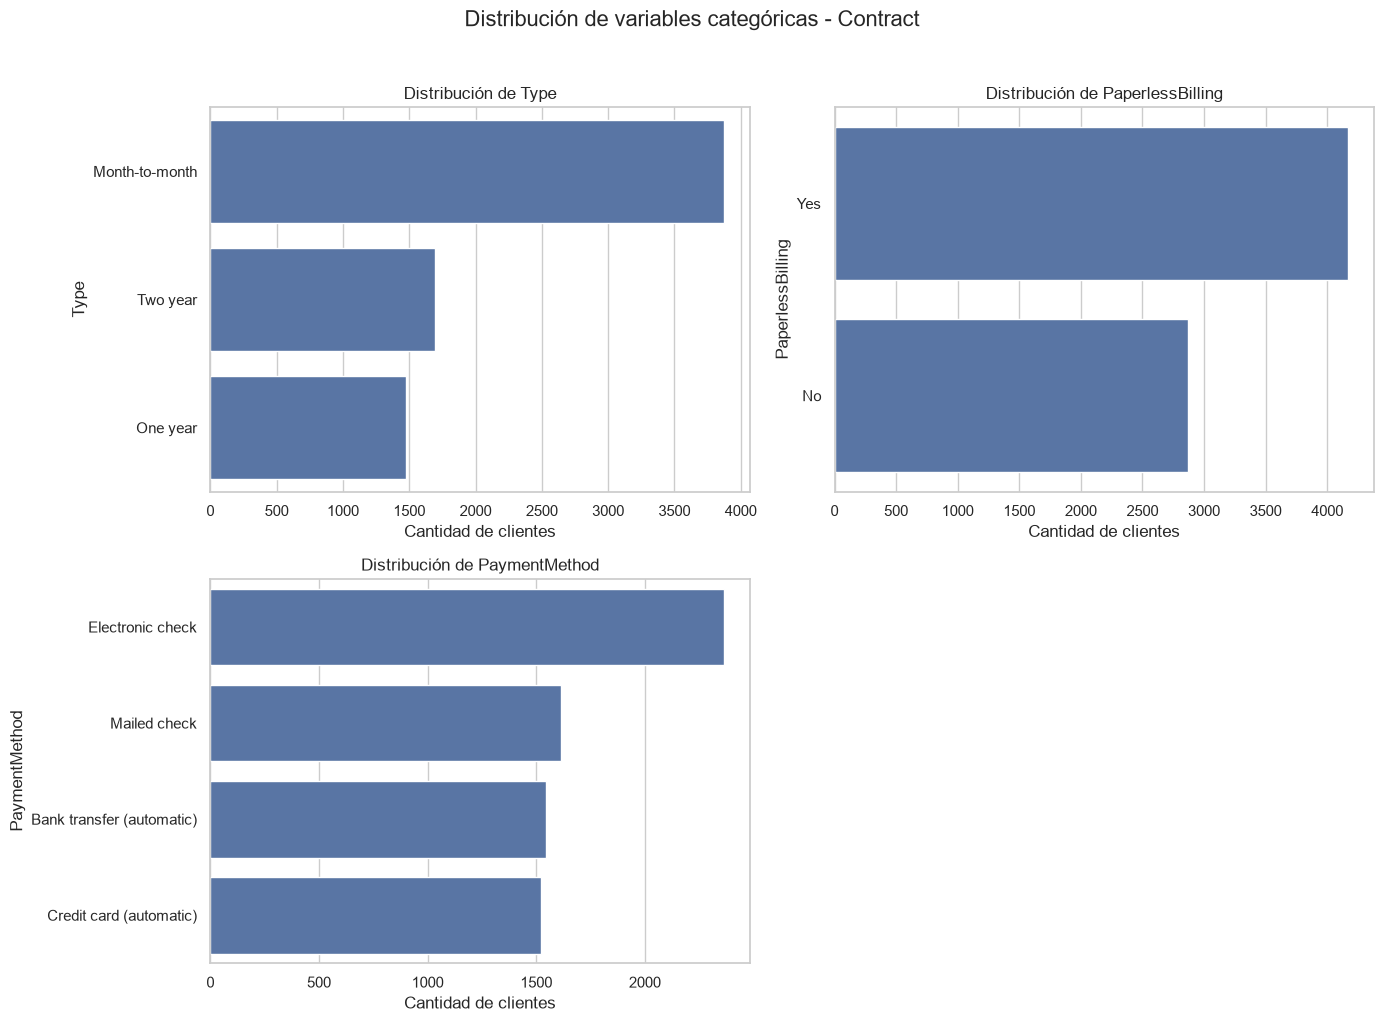

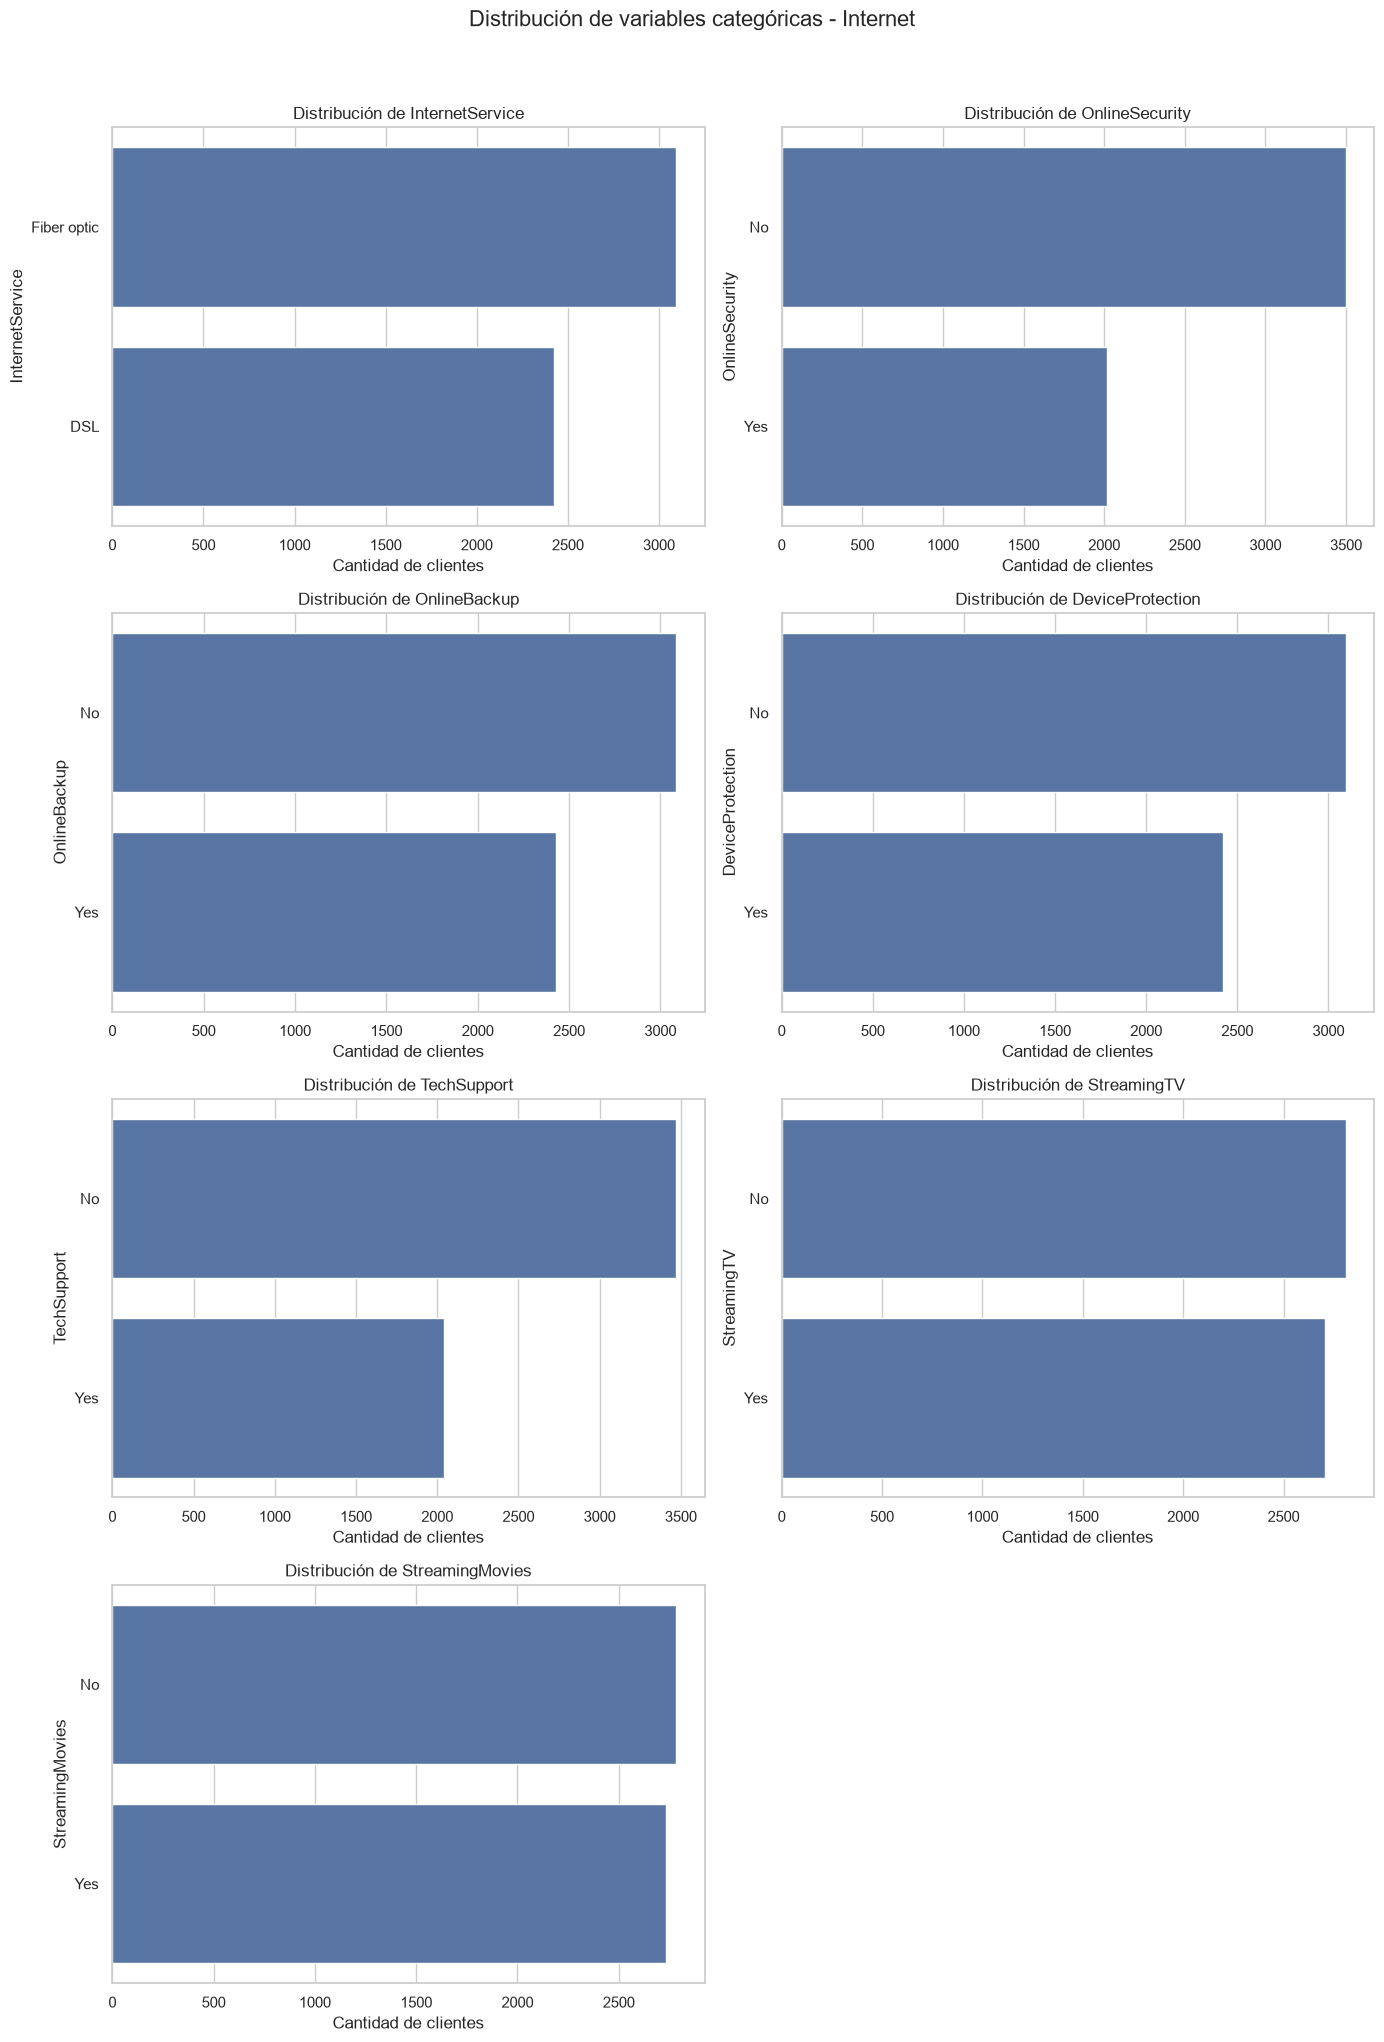

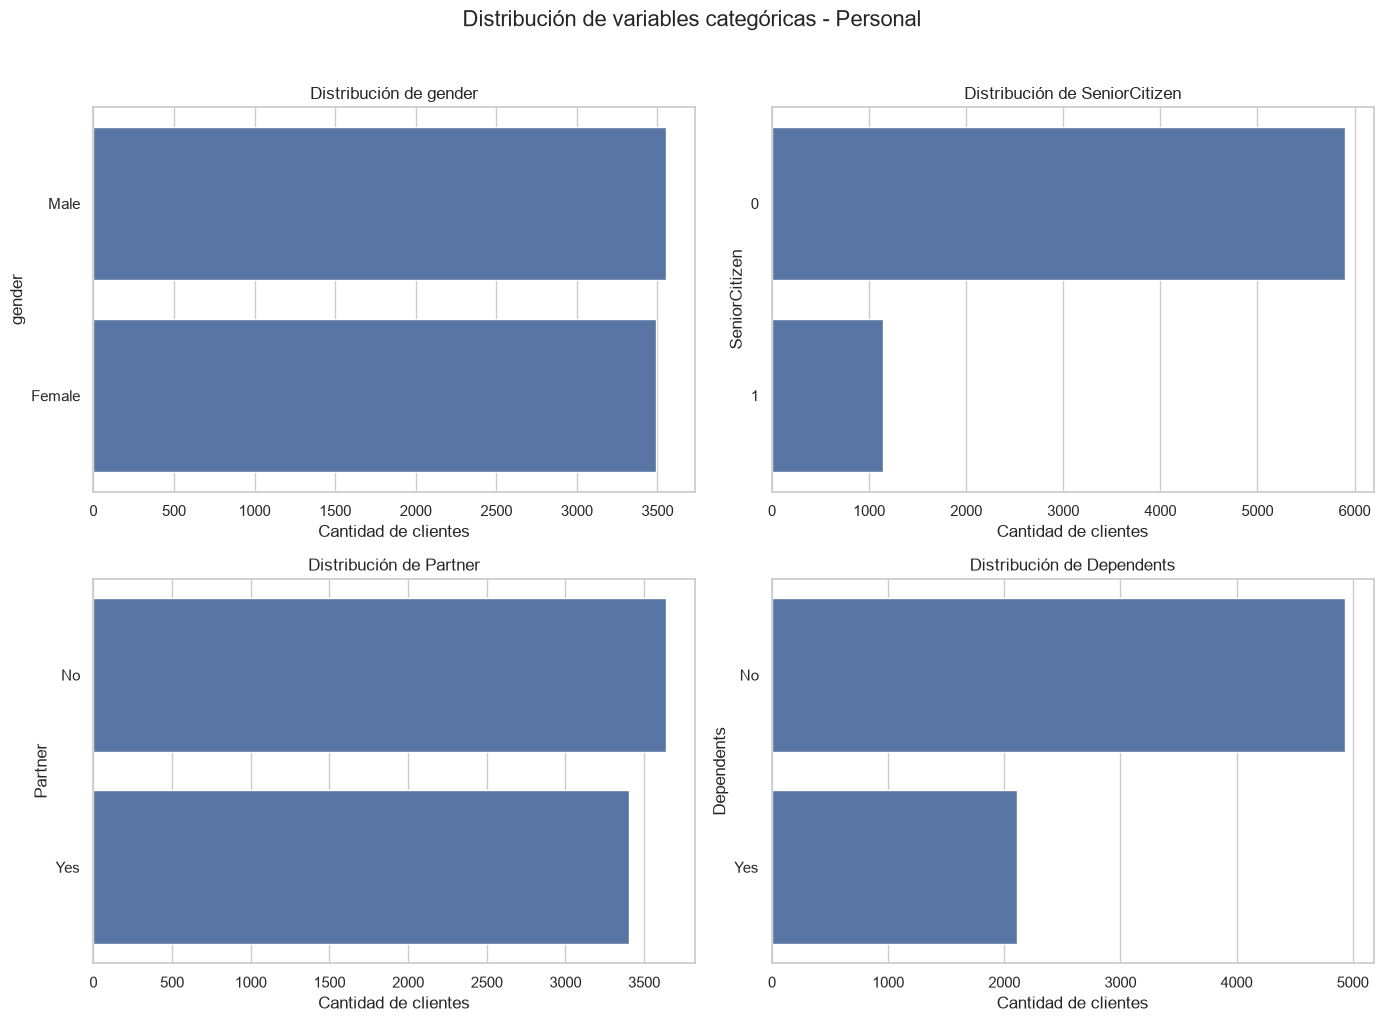

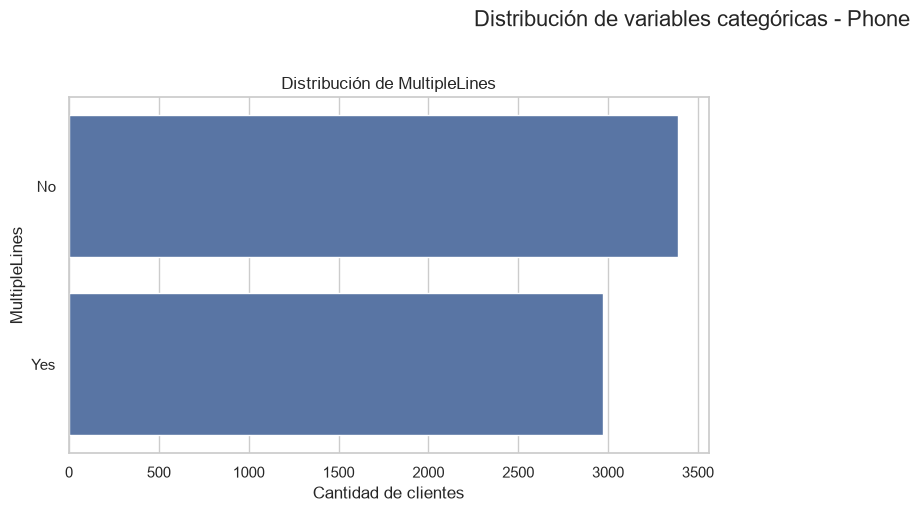

In [98]:
# Distribución de variables categóricas

for name, df in datasets.items():

    categorical_columns = [
        column
        for column in df.select_dtypes(include=['str', 'category']).columns
        if column != 'customerID'
    ]

    # Número de gráficas
    n_plots = len(categorical_columns)

    # Dos columnas y las filas necesarias
    n_cols = 2
    n_rows = int(np.ceil(n_plots / n_cols))

    # Crear figura
    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 5 * n_rows)
    )

    # Convertir axes en arreglo 1D para facilitar el recorrido
    axes = np.array(axes).reshape(-1)

    # Crear cada gráfica
    for ax, column in zip(axes, categorical_columns):

        order = df[column].value_counts().index

        sns.countplot(
            data=df,
            y=column,
            order=order,
            ax=ax
        )

        ax.set_title(f'Distribución de {column}')
        ax.set_xlabel('Cantidad de clientes')
        ax.set_ylabel(column)

    # Ocultar espacios sobrantes
    for ax in axes[n_plots:]:
        ax.set_visible(False)

    # Título general del DataFrame
    fig.suptitle(
        f'Distribución de variables categóricas - {name}',
        fontsize=16,
        y=1.02
    )

    plt.tight_layout()
    plt.show()

#### 4.3.2 Variables numéricas

In [99]:
contract_numeric = [
    column
    for column in contract.select_dtypes(include='number').columns
    if column != 'SeniorCitizen'
]

contract_numeric

['MonthlyCharges', 'TotalCharges']

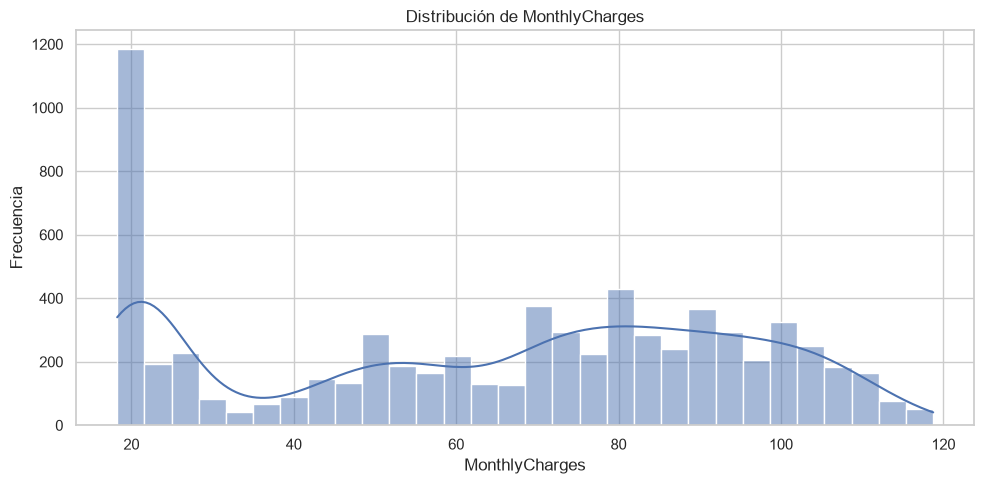

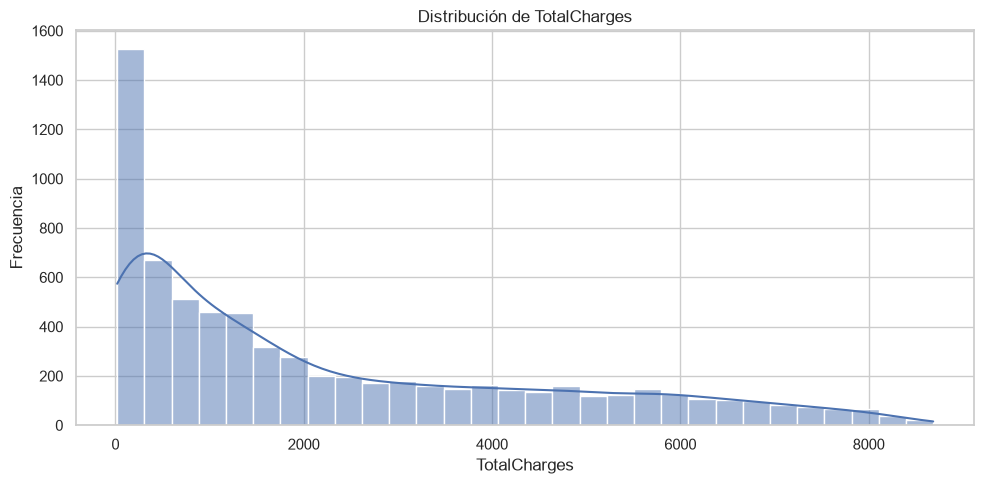

In [100]:
# Histogramas de variables numéricas

numeric_columns = ['MonthlyCharges', 'TotalCharges']

for column in numeric_columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(data=contract,
                 x=column,
                 bins=30,
                 kde=True )

    plt.title(f'Distribución de {column}')
    plt.xlabel(column)
    plt.ylabel('Frecuencia')

    plt.tight_layout()
    plt.show()

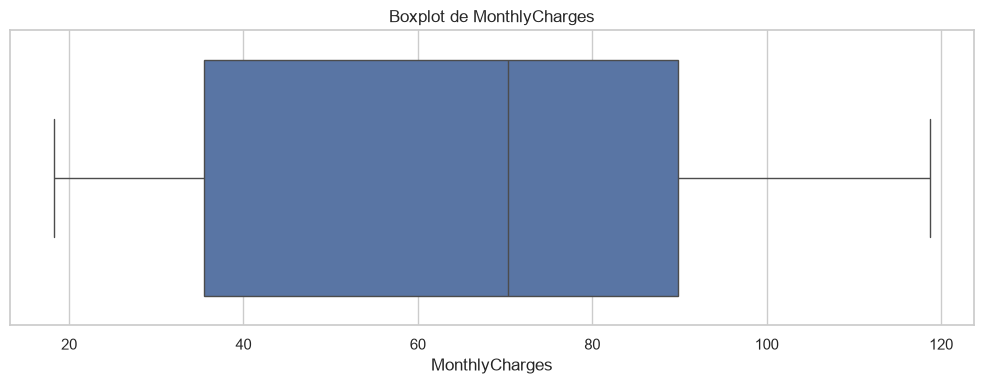

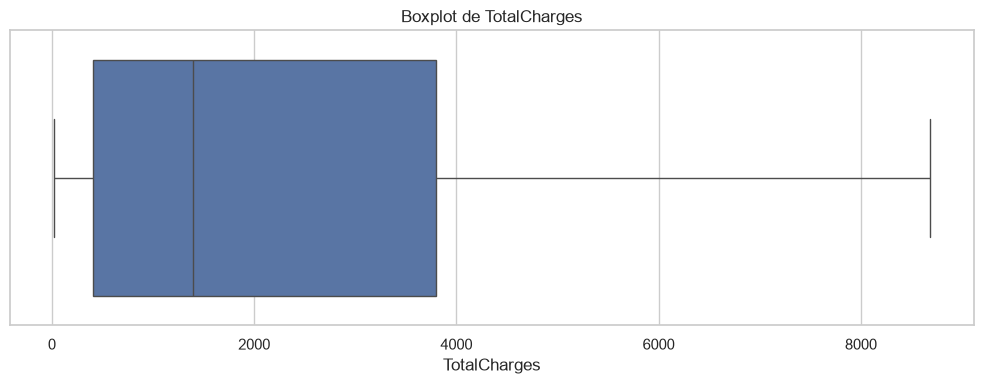

In [101]:
for column in numeric_columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=contract,
        x=column
    )

    plt.title(f'Boxplot de {column}')
    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

#### 4.3.3 Distribución de `BeginDate` y `EndDate`

In [102]:
# Crea columnas temporales para agrupar
df_BeginDate = contract[['BeginDate']].copy()
df_BeginDate['Year'] = df_BeginDate['BeginDate'].dt.year

# Agrupa y cuenta
begin_year_df = (df_BeginDate.groupby('Year', sort=True).size().reset_index(name='Count'))

display(begin_year_df)

,Year,Count
0,2013,8
1,2014,1344
2,2015,852
3,2016,763
4,2017,845
5,2018,1030
6,2019,1957
7,2020,244


In [103]:
def analizar_contratos_por_fecha(df, columna_fecha):
    
    # =========================================================
    # PREPARACIÓN DE DATOS
    # =========================================================
    
    # Copia para no modificar el DataFrame original
    data = df[[columna_fecha]].copy()
    
    # Asegurar que la columna sea datetime
    data[columna_fecha] = pd.to_datetime(data[columna_fecha])
    
    # Crear columna Año
    data['Year'] = data[columna_fecha].dt.year.astype('Int64')
    data['Year'] = data['Year'].fillna(0).astype('Int64')
    
    # Tabla de contratos por año
    year_df = (data.groupby('Year', sort=True).size().reset_index(name='Count'))
    
    # Mostrar tabla
    display(year_df)
    
    
    # =========================================================
    # AGRUPACIÓN POR AÑO-MES
    # =========================================================
    
    # Eliminar fechas nulas antes de crear el periodo
    data_month = data.dropna(subset=[columna_fecha]).copy()
    
    # Crear periodo Año-Mes
    data_month['Year_Month'] = (data_month[columna_fecha].dt.to_period('M'))
    
    # Agrupar y contar contratos por mes
    agrupado_ym = (data_month.groupby('Year_Month', sort=True).size().reset_index(name='Count'))
    
    # Convertir Period a datetime para graficar
    agrupado_ym['Year_Month'] = (agrupado_ym['Year_Month'].dt.to_timestamp())
    
    
    # =========================================================
    # GRÁFICO 1: TENDENCIA MENSUAL
    # =========================================================
    
    fig, ax = plt.subplots(figsize=(14, 6))
    
    ax.plot(agrupado_ym['Year_Month'],
            agrupado_ym['Count'],
            marker='o',
            linestyle='-',
            color='steelblue',
            linewidth=2,
            markersize=6)
    
    ax.fill_between(agrupado_ym['Year_Month'], agrupado_ym['Count'], color='steelblue', alpha=0.2)
    
    ax.set_title(f'Tendencia de Contratos por {columna_fecha} Año-Mes', fontsize=15, fontweight='bold')
    
    ax.set_xlabel('Año')
    ax.set_ylabel('Cantidad de Contratos')
    
    # Mostrar únicamente una etiqueta por año
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    
    
    # =========================================================
    # GRÁFICO 2: BOXPLOT
    # =========================================================
    
    fig, ax = plt.subplots(figsize=(8, 6))
    
    ax.boxplot(
        agrupado_ym['Count'],
        patch_artist=True,
        boxprops=dict(facecolor='lightcoral',
                      color='darkred'
        ),
        medianprops=dict(color='white', linewidth=2),
        whiskerprops=dict(color='darkred'),
        capprops=dict(color='darkred'),
        flierprops=dict(marker='o',
                        markersize=4,
                        color='darkred',
                        alpha=0.5)
    )
    
    ax.set_title(f'Distribución de Contratos Mensuales - {columna_fecha}', fontsize=15, fontweight='bold')
    
    ax.set_ylabel('Cantidad de Contratos')
    ax.set_xticklabels(['Conteos'])
    
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    
    plt.tight_layout()
    plt.show()
    
    
    # =========================================================
    # RETORNAR RESULTADOS
    # =========================================================
    
    return year_df, agrupado_ym

,Year,Count
0,2013,8
1,2014,1344
2,2015,852
3,2016,763
4,2017,845
5,2018,1030
6,2019,1957
7,2020,244


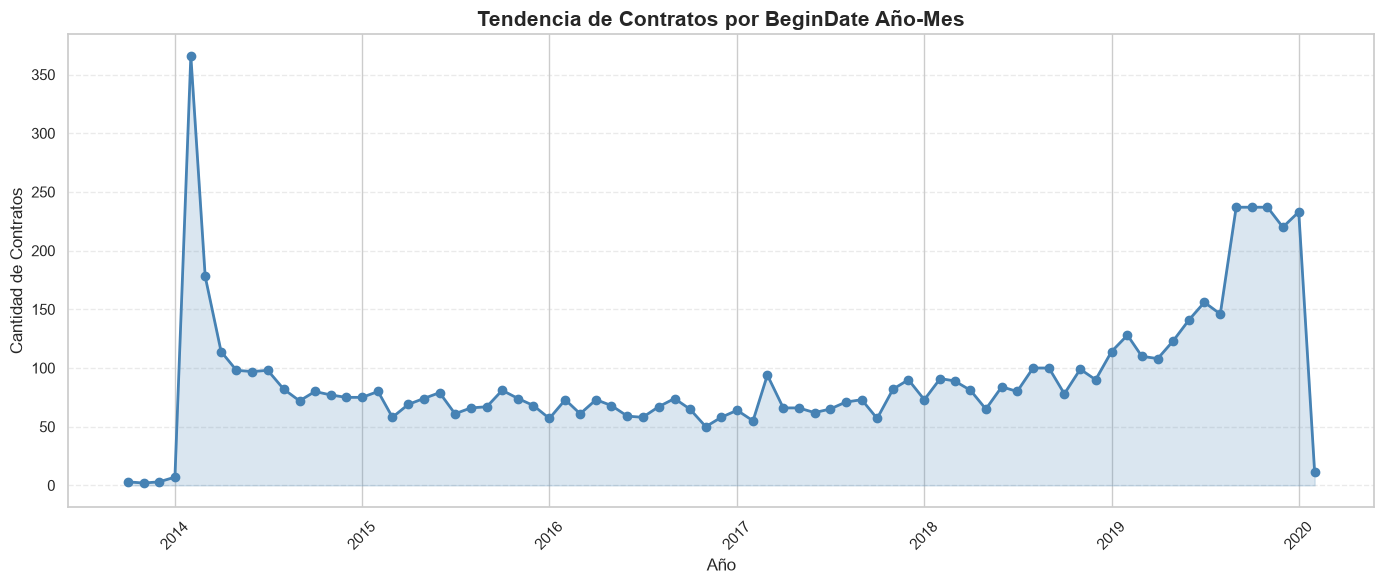

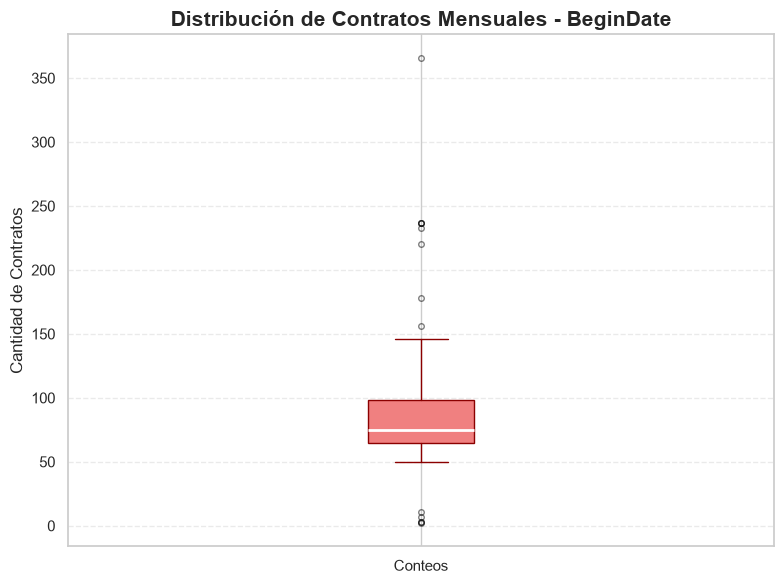

In [104]:
begin_year_df, begin_ym_df = analizar_contratos_por_fecha(contract, 'BeginDate')

,Year,Count
0,0,5174
1,2019,1409
2,2020,460


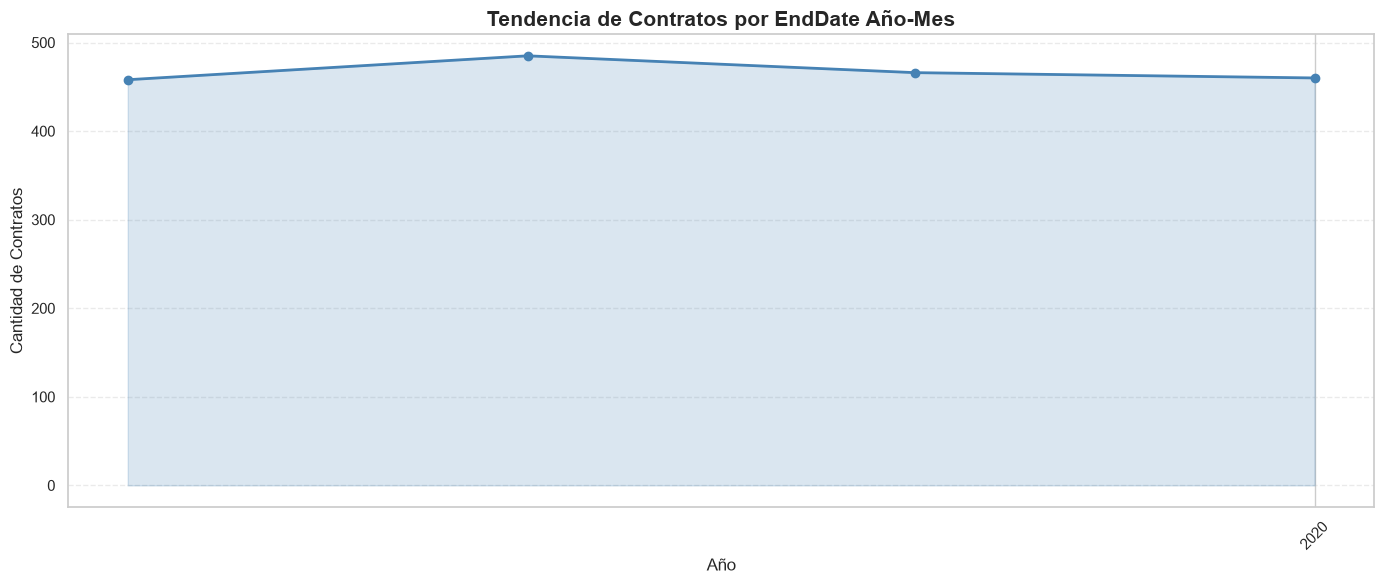

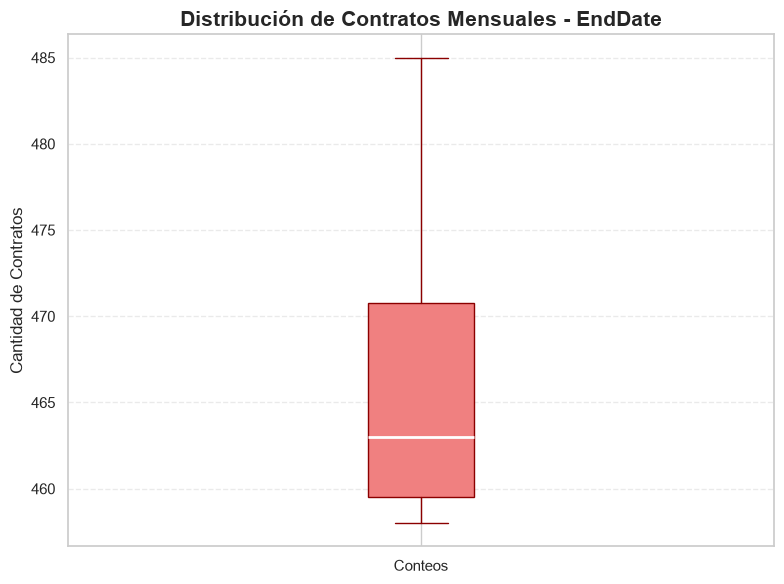

In [105]:
begin_year_df, begin_ym_df = analizar_contratos_por_fecha(contract, 'EndDate')

### 4.5 Relaciones entre variables

,MonthlyCharges,TotalCharges
MonthlyCharges,1.00,0.65
TotalCharges,0.65,1.00


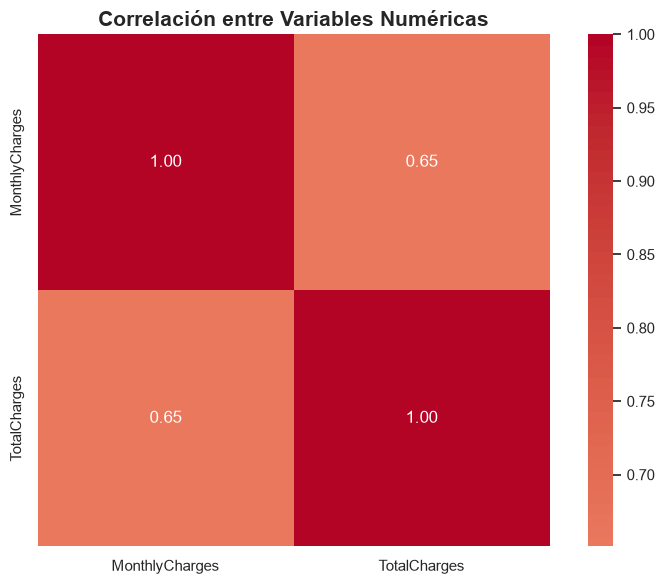

In [106]:
numeric_columns = ['MonthlyCharges', 'TotalCharges']

correlation_matrix = contract[numeric_columns].corr()

display(correlation_matrix)


# Heatmap de correlación

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True
)

plt.title(
    'Correlación entre Variables Numéricas',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

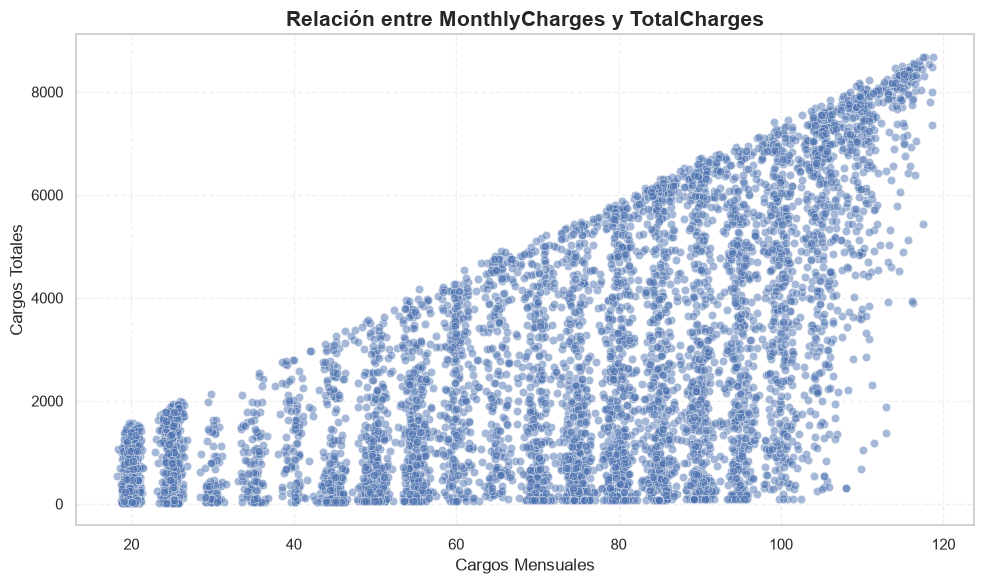

In [107]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=contract,
                x='MonthlyCharges',
                y='TotalCharges',
                alpha=0.5 )

plt.title('Relación entre MonthlyCharges y TotalCharges', fontsize=15, fontweight='bold')

plt.xlabel('Cargos Mensuales')
plt.ylabel('Cargos Totales')

plt.grid(axis='both', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

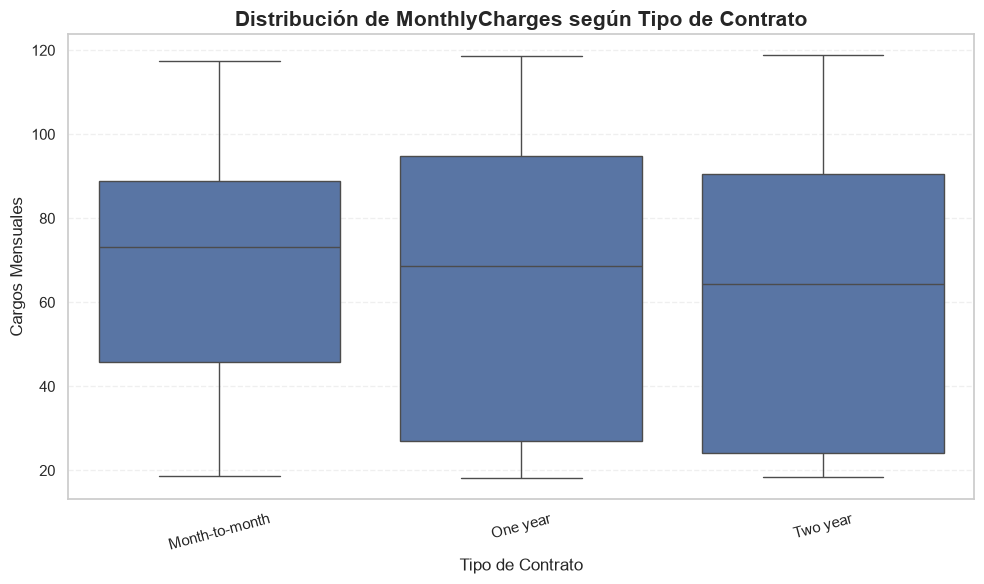

In [108]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=contract,
            x='Type',
            y='MonthlyCharges')

plt.title('Distribución de MonthlyCharges según Tipo de Contrato', fontsize=15, fontweight='bold')

plt.xlabel('Tipo de Contrato')
plt.ylabel('Cargos Mensuales')

plt.xticks(rotation=15)

plt.grid(axis='y',linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

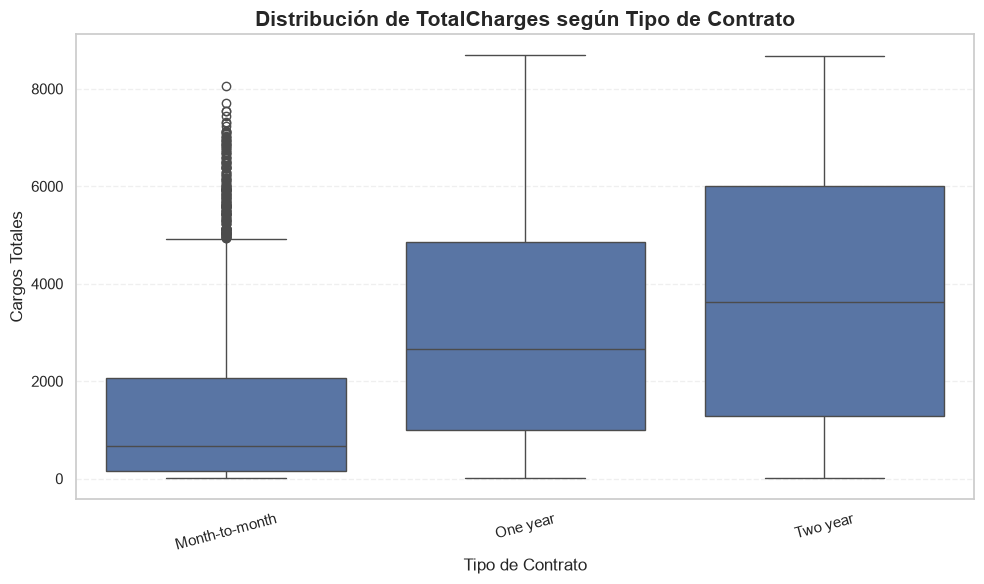

In [109]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=contract,
            x='Type',
            y='TotalCharges')

plt.title('Distribución de TotalCharges según Tipo de Contrato', fontsize=15, fontweight='bold')

plt.xlabel('Tipo de Contrato')
plt.ylabel('Cargos Totales')

plt.xticks(rotation=15)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

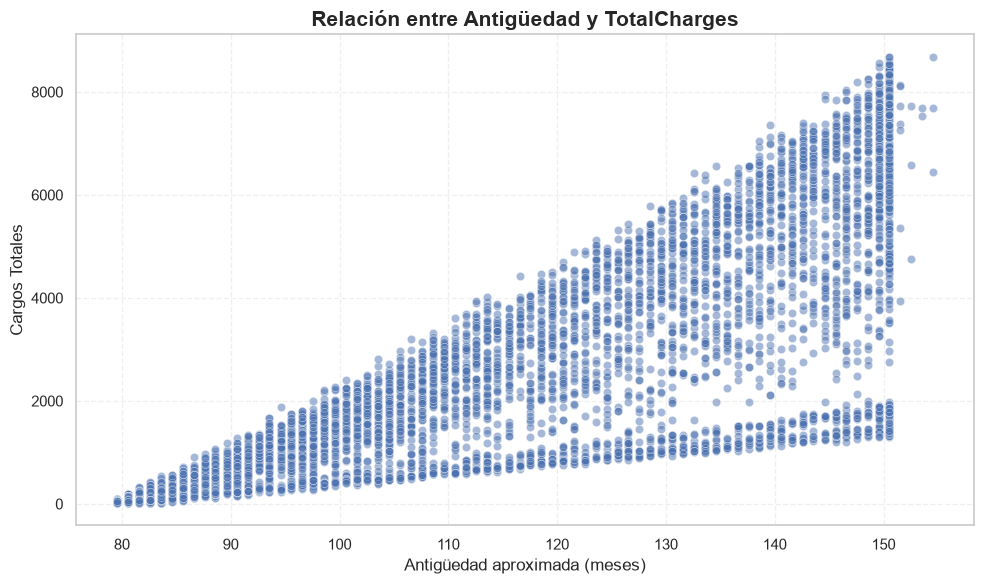

In [110]:
contract_relation = contract[['BeginDate', 'MonthlyCharges', 'TotalCharges']].copy()

contract_relation['BeginDate'] = pd.to_datetime(contract_relation['BeginDate'])

# Calcular antigüedad aproximada en meses
today = pd.Timestamp.today()

contract_relation['TenureMonths'] = ((today - contract_relation['BeginDate']).dt.days / 30.44)

plt.figure(figsize=(10, 6))

sns.scatterplot(data=contract_relation,
                x='TenureMonths',
                y='TotalCharges',
                alpha=0.5 )

plt.title('Relación entre Antigüedad y TotalCharges', fontsize=15, fontweight='bold')

plt.xlabel('Antigüedad aproximada (meses)')
plt.ylabel('Cargos Totales')

plt.grid(axis='both', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

### 4.6 Hallazgos del EDA

El análisis exploratorio de datos permitió identificar los siguientes hallazgos principales:

* **Calidad de los datos:** no se encontraron registros duplicados completos ni `customerID` duplicados en ninguno de los datasets analizados. `BeginDate` no presenta valores ausentes, mientras que `EndDate` contiene **5,174 valores nulos**, correspondientes a clientes que no tienen registrada una fecha de finalización. `TotalCharges` presenta **11 valores ausentes**, por lo que esta variable requiere consideración durante las etapas posteriores del análisis.

* **Tipo de contrato:** la mayor parte de los clientes tiene un contrato **Month-to-month (55.02%)**, seguido de **Two year (24.07%)** y **One year (20.91%)**. Esto muestra un predominio de contratos de corta duración y representa una variable relevante para analizar el comportamiento de los clientes.

* **Métodos de pago:** el método más utilizado es **Electronic check (33.58%)**, seguido de **Mailed check (22.89%)**, **Bank transfer (automatic) (21.92%)** y **Credit card (automatic) (21.61%)**. La distribución es relativamente equilibrada entre los métodos de pago, aunque el pago mediante cheque electrónico presenta la mayor participación.

* **Servicios de Internet:** entre los clientes que cuentan con servicio de Internet, **Fiber optic representa el 56.12%** y **DSL el 43.88%**. Además, servicios adicionales como `OnlineSecurity` y `TechSupport` presentan una mayor proporción de clientes que no los utilizan.

* **Variables numéricas:** las variables `MonthlyCharges` y `TotalCharges` presentan una relación positiva. La matriz de correlación muestra un coeficiente de aproximadamente **0.65**, lo que indica una relación positiva de intensidad moderada. El gráfico de dispersión confirma que, en general, los clientes con mayores cargos mensuales tienden a acumular mayores cargos totales.

* **Relación entre tipo de contrato y cargos:** las distribuciones de `MonthlyCharges` y `TotalCharges` muestran diferencias entre los distintos tipos de contrato. Esto sugiere que el tipo de contrato está relacionado con el comportamiento de los cargos y puede ser una variable importante para el análisis posterior.

* **Comportamiento temporal:** los registros de `BeginDate` se concentran principalmente entre **2014 y 2020**, con un incremento particularmente notable en **2019**, año que concentra 1,957 registros. Para `EndDate`, las fechas disponibles corresponden únicamente a **2019 y 2020**, mientras que la mayoría de los registros no tiene fecha de finalización.

* **Antigüedad y cargos totales:** el análisis de la relación entre la antigüedad del cliente y `TotalCharges` muestra una tendencia positiva: conforme aumenta el tiempo de permanencia, los cargos totales tienden a incrementarse. Esto es consistente con la acumulación de cargos a lo largo del tiempo.

#### Conclusión del EDA

En conjunto, el EDA muestra que **el tipo de contrato, los cargos mensuales, los cargos totales, la antigüedad y las características de los servicios contratados son variables relevantes para comprender el comportamiento de los clientes**. El predominio de contratos `Month-to-month`, junto con la presencia de un número considerable de clientes sin `EndDate`, proporciona elementos importantes para continuar con el análisis de permanencia y abandono de clientes.

Estos hallazgos servirán como base para identificar las variables con mayor potencial predictivo y definir las siguientes etapas del proyecto.


## 5. Preparación de los datos y definición del problema de Machine Learning

### 5.1 Definición de la variable objetivo y preparación de los datos

In [111]:
# Crear copia de los datasets
df_contract = contract.copy()
df_personal = personal.copy()
df_internet = internet.copy()
df_phone = phone.copy()

In [112]:
# Revisar valores de EndDate
display(df_contract['EndDate'].value_counts(dropna=False))

# Revisar porcentaje de valores nulos
print(
    f"Valores nulos en EndDate: "
    f"{df_contract['EndDate'].isna().sum():,} "
    f"({df_contract['EndDate'].isna().mean() * 100:.2f}%)"
)

EndDate
NaT           5174
2019-11-01     485
2019-12-01     466
2020-01-01     460
2019-10-01     458
Name: count, dtype: int64

Valores nulos en EndDate: 5,174 (73.46%)


In [113]:
# Crear variable objetivo Churn
df_contract['Churn'] = df_contract['EndDate'].notna().astype(int)

# 1 = cliente que abandonó
# 0 = cliente que permanece

In [114]:
# Revisar distribución de Churn
churn_summary = (df_contract['Churn'].value_counts().sort_index().reset_index())

churn_summary.columns = ['Churn', 'Count']

churn_summary['Percentage'] = (churn_summary['Count'] / churn_summary['Count'].sum() * 100)

display(churn_summary)

,Churn,Count,Percentage
0,0,5174,73.46
1,1,1869,26.54


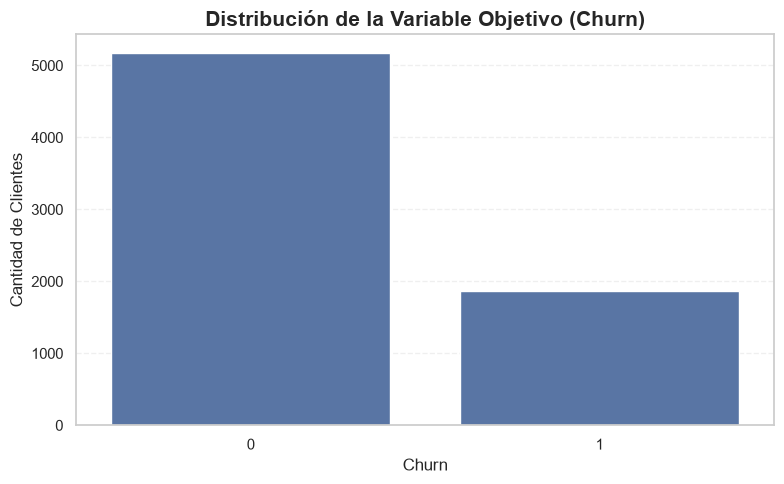

In [115]:
plt.figure(figsize=(8, 5))

sns.countplot( data=df_contract,
              x='Churn' )

plt.title('Distribución de la Variable Objetivo (Churn)', fontsize=15, fontweight='bold')

plt.xlabel('Churn')
plt.ylabel('Cantidad de Clientes')

plt.grid(axis='y',
         linestyle='--',
         alpha=0.3 )

plt.tight_layout()
plt.show()

### 5.2 Balance de clases y división de los datos

In [116]:
# Generación de nuevas variables temporales
df_contract['BeginYear'] = (df_contract['BeginDate'].dt.year)

df_contract['BeginMonth'] = (df_contract['BeginDate'].dt.month)

df_contract['BeginQuarter'] = (df_contract['BeginDate'].dt.quarter)

df_contract = df_contract.drop(columns=['BeginDate'], errors='ignore')


# Integración de información de clientes
data = df_contract.merge(df_personal, on='customerID', how='left')

data = data.merge(df_internet, on='customerID', how='left')

data = data.merge(df_phone, on='customerID', how='left')

# Generando variable TotalServices
service_columns = ['OnlineSecurity',
                   'OnlineBackup',
                   'DeviceProtection',
                   'TechSupport',
                   'StreamingTV',
                   'StreamingMovies']

data['TotalServices'] = (data[service_columns].eq('Yes').sum(axis=1))

# Revisar dimensiones
print(f'Filas: {data.shape[0]:,}')
print(f'Columnas: {data.shape[1]:,}')


# Revisar estructura
display(data.head())

Filas: 7,043
Columnas: 24


,customerID,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,BeginYear,BeginMonth,BeginQuarter,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines,TotalServices
0,7590-VHVEG,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,0,2020,1,1,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN,1
1,5575-GNVDE,NaT,One year,No,Mailed check,56.95,"1,889.50",0,2017,4,2,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No,2
2,3668-QPYBK,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,1,2019,10,4,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No,2
3,7795-CFOCW,NaT,One year,No,Bank transfer (automatic),42.30,"1,840.75",0,2016,5,2,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN,3
4,9237-HQITU,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,1,2019,9,3,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No,0


In [117]:
# Validar duplicados de customerID

print('CustomerID duplicados:', data['customerID'].duplicated().sum())

CustomerID duplicados: 0


In [118]:
class_distribution = (data['Churn'].value_counts(normalize=True).sort_index() * 100)

print('Distribución porcentual de las clases:')
display(class_distribution)

Distribución porcentual de las clases:


Churn
0   73.46
1   26.54
Name: proportion, dtype: float64

In [119]:
# Datos fatantes de serivicios
service_columns = ['InternetService',
                   'OnlineSecurity',
                   'OnlineBackup',
                   'DeviceProtection',
                   'TechSupport',
                   'StreamingTV',
                   'StreamingMovies',
                   'MultipleLines']

data[service_columns] = data[service_columns].fillna('Missing')

In [120]:
target = data['Churn']

# Variables que NO deben utilizarse como predictores
columns_to_drop = ['Churn',
                   'EndDate',
                   'customerID']

features = data.drop(columns=columns_to_drop, errors='ignore')

In [121]:
features_train, features_test, target_train, target_test = train_test_split(features,
                                                                            target,
                                                                            test_size=0.20,
                                                                            random_state=42,
                                                                            stratify=target)

### 5.3 Preprocesamiento y Feature Engineering

In [122]:
# Variables numéricas
numeric_features = features.select_dtypes(include=['int64', 'float64', 'Int64']).columns.tolist()

# Variables categóricas
categorical_features = features.select_dtypes(include=['object', 'category', 'string']).columns.tolist()

print('Variables numéricas:')
print(numeric_features)

print('\nVariables categóricas:')
print(categorical_features)

Variables numéricas:
['MonthlyCharges', 'TotalCharges', 'TotalServices']

Variables categóricas:
['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']


In [123]:
# Pipeline para variables numéricas

numeric_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

In [124]:
# Pipeline para variables categóricas

categorical_transformer = Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')), ('onehot',OneHotEncoder(handle_unknown='ignore'))])

In [125]:
# Preprocesamiento de datos

preprocessor = ColumnTransformer(transformers=[('num', numeric_transformer, numeric_features), ('cat', categorical_transformer, categorical_features)])

## 6. Entrenamiento y evaluación de modelos

### 6.1 Modelos y baseline

In [126]:
def evaluar_modelo(nombre_modelo,
                   pipeline,
                   features_test,
                   target_test,
                   mejores_parametros=None,
                   roc_auc_cv=None ):
    """
    Evalúa un modelo previamente entrenado utilizando
    el conjunto de prueba.
    """

    # =====================================================
    # PREDICCIONES
    # =====================================================

    target_pred = pipeline.predict(features_test)

    # Probabilidad de la clase positiva
    target_prob = pipeline.predict_proba(features_test)[:, 1]

    # =====================================================
    # MÉTRICAS
    # =====================================================

    accuracy = accuracy_score(target_test, target_pred)

    precision = precision_score(target_test, target_pred, zero_division=0)

    recall = recall_score(target_test, target_pred, zero_division=0)

    f1 = f1_score(target_test, target_pred, zero_division=0)

    roc_auc = roc_auc_score(target_test, target_prob)
    
    matrix = confusion_matrix(target_test, target_pred)

    # =====================================================
    # RESULTADOS
    # =====================================================

    resultado = {
        'Model': nombre_modelo,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-score': f1,
        'ROC-AUC': roc_auc,
        'ROC-AUC CV': roc_auc_cv,
        'Best Parameters': mejores_parametros,
        'Confusion Matrix': matrix
    }

    return pipeline, resultado

In [127]:
def optimizar_modelo(
        nombre_modelo,
        modelo,
        parametros,
        preprocessor,
        features_train,
        target_train,
        cv=5 ):
    """
    Construye un Pipeline y busca los mejores hiperparámetros
    utilizando ROC-AUC como métrica principal.
    """

    # =====================================================
    # PIPELINE
    # =====================================================

    pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('model', modelo)])

    # =====================================================
    # GRID SEARCH
    # =====================================================

    grid_search = GridSearchCV(estimator=pipeline,
                               param_grid=parametros,
                               scoring='roc_auc',
                               cv=cv,
                               n_jobs=-1,
                               verbose=1 )

    # =====================================================
    # ENTRENAMIENTO
    # =====================================================

    grid_search.fit(features_train, target_train)

    print(f'\n{"=" * 60}')
    print(f'Modelo: {nombre_modelo}')
    print(f'{"=" * 60}')

    print('\nMejores parámetros:')
    print(grid_search.best_params_)

    print(
        f'\nMejor ROC-AUC CV: '
        f'{grid_search.best_score_:.4f}'
    )

    return grid_search.best_estimator_, grid_search.best_params_, grid_search.best_score_

### 6.2 Evaluación y comparación de modelos

In [128]:

# =====================================================
# LOGISTIC REGRESSION
# =====================================================

logistic_regression = LogisticRegression(max_iter=2000,
                                         class_weight='balanced',
                                         random_state=42 )

parametros_logistic = {
    'model__C': [0.01, 0.1, 1, 10, 100],

    'model__solver': ['liblinear', 'lbfgs']
}

# =====================================================
# RANDOM FOREST
# =====================================================

random_forest = RandomForestClassifier(class_weight='balanced',
                                       random_state=42,
                                       n_jobs=-1 )

parametros_random_forest = {
    'model__n_estimators': [100, 200, 300],
    'model__max_depth': [None, 5, 10, 15],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5],
    'model__max_features': ['sqrt', 'log2']
}

# =====================================================
# GRADIENT BOOSTING
# =====================================================

gradient_boosting = GradientBoostingClassifier(random_state=42)

parametros_gradient_boosting = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_depth': [2, 3, 4],
    'model__min_samples_leaf': [1, 5, 10, 20],
    'model__subsample': [0.8, 1.0]
}

# =====================================================
# DECISION TREE
# =====================================================

decision_tree = DecisionTreeClassifier(random_state=42,
                                       class_weight='balanced' )
parametros_decision_tree = {
    'model__max_depth': [3, 5, 10, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5]
}

# =====================================================
# DUMMY
# =====================================================

dummy = DummyClassifier(strategy='most_frequent')

In [129]:
# =====================================================
# LOGISTIC REGRESSION
# =====================================================

logistic_best, logistic_params, logistic_cv = optimizar_modelo(
    nombre_modelo='Logistic Regression',
    modelo=logistic_regression,
    parametros=parametros_logistic,
    preprocessor=preprocessor,
    features_train=features_train,
    target_train=target_train
)

# =====================================================
# RANDOM FOREST
# =====================================================

random_forest_best, random_forest_params, random_forest_cv = optimizar_modelo(
    nombre_modelo='Random Forest',
    modelo=random_forest,
    parametros=parametros_random_forest,
    preprocessor=preprocessor,
    features_train=features_train,
    target_train=target_train
)

# =====================================================
# GRADIENT BOOSTING
# =====================================================

gradient_boosting_best, gradient_boosting_params, gradient_boosting_cv = optimizar_modelo(
    nombre_modelo='Gradient Boosting',
    modelo=gradient_boosting,
    parametros=parametros_gradient_boosting,
    preprocessor=preprocessor,
    features_train=features_train,
    target_train=target_train
)

# =====================================================
# DECISION TREE
# =====================================================

decision_tree_best, decision_tree_params, decision_tree_cv = optimizar_modelo(
    nombre_modelo='Decision Tree',
    modelo=decision_tree,
    parametros=parametros_decision_tree,
    preprocessor=preprocessor,
    features_train=features_train,
    target_train=target_train
)




# =====================================================
# RESULTADOS
# =====================================================


resultados = []

resultados.append(
    evaluar_modelo('Logistic Regression',
                   logistic_best,
                   features_test,
                   target_test,
                   logistic_params,
                   logistic_cv
    )
)

resultados.append(
    evaluar_modelo('Random Forest',
                   random_forest_best,
                   features_test,
                   target_test,
                   random_forest_params,
                   random_forest_cv
    )
)

resultados.append(
    evaluar_modelo('Gradient Boosting',
                   gradient_boosting_best,
                   features_test,
                   target_test,
                   gradient_boosting_params,
                   gradient_boosting_cv
    )
)

resultados.append(
    evaluar_modelo('Decision Tree',
                   decision_tree_best,
                   features_test,
                   target_test,
                   decision_tree_params,
                   decision_tree_cv
    )
)


# =====================================================
# DUMMY
# =====================================================

dummy_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor),
           ('model', dummy)
    ]
)

dummy_pipeline.fit(features_train,target_train)

resultados.append(
    evaluar_modelo(
        'Dummy Classifier',
        dummy_pipeline,
        features_test,
        target_test,
        mejores_parametros=None,
        roc_auc_cv=None
    )
)


Fitting 5 folds for each of 10 candidates, totalling 50 fits

Modelo: Logistic Regression

Mejores parámetros:
{'model__C': 10, 'model__solver': 'liblinear'}

Mejor ROC-AUC CV: 0.8397
Fitting 5 folds for each of 216 candidates, totalling 1080 fits

Modelo: Random Forest

Mejores parámetros:
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Mejor ROC-AUC CV: 0.8443
Fitting 5 folds for each of 288 candidates, totalling 1440 fits

Modelo: Gradient Boosting

Mejores parámetros:
{'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__min_samples_leaf': 20, 'model__n_estimators': 300, 'model__subsample': 0.8}

Mejor ROC-AUC CV: 0.8502
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Modelo: Decision Tree

Mejores parámetros:
{'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}

Mejor ROC-AUC CV: 0.8260


In [130]:
resultados_df = pd.DataFrame([resultado[1] for resultado in resultados])

# Ordenar por ROC-AUC
resultados_df = resultados_df.sort_values('ROC-AUC', ascending=False).reset_index(drop=True)

display(resultados_df)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,ROC-AUC CV,Best Parameters,Confusion Matrix
0,Gradient Boosting,0.80,0.67,0.52,0.58,0.85,0.85,"{'model__learning_rate': 0.03, 'model__max_dep...","[[940, 95], [181, 193]]"
1,Random Forest,0.75,0.52,0.77,0.62,0.84,0.84,"{'model__max_depth': 10, 'model__max_features'...","[[768, 267], [85, 289]]"
2,Logistic Regression,0.73,0.50,0.78,0.61,0.83,0.84,"{'model__C': 10, 'model__solver': 'liblinear'}","[[742, 293], [83, 291]]"
3,Decision Tree,0.76,0.53,0.73,0.61,0.83,0.83,"{'model__max_depth': 5, 'model__min_samples_le...","[[791, 244], [101, 273]]"
4,Dummy Classifier,0.73,0.00,0.00,0.00,0.50,NaN,None,"[[1035, 0], [374, 0]]"


### 6.3 Selección e interpretación del mejor modelo

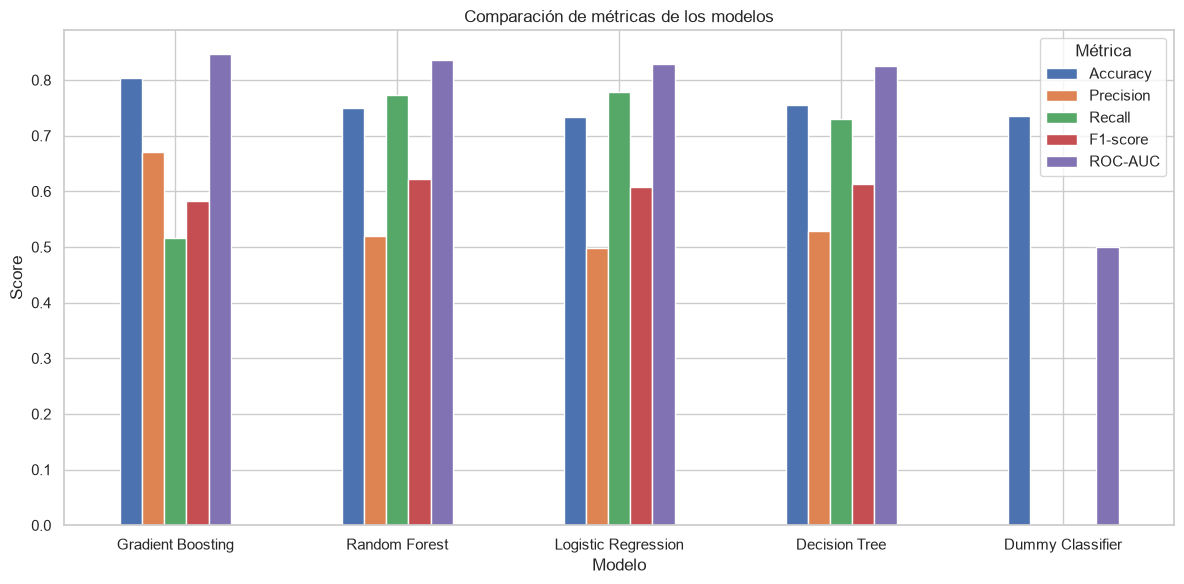

In [131]:
metricas = ['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']

resultados_plot = resultados_df.set_index('Model')[metricas]

ax = resultados_plot.plot(kind='bar', figsize=(12, 6))

plt.title('Comparación de métricas de los modelos')
plt.xlabel('Modelo')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(title='Métrica')
plt.tight_layout()
plt.show()

In [132]:
resultados_df['Diferencia CV-Test'] = (
    resultados_df['ROC-AUC CV'] - resultados_df['ROC-AUC']
)

display(resultados_df)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,ROC-AUC CV,Best Parameters,Confusion Matrix,Diferencia CV-Test
0,Gradient Boosting,0.80,0.67,0.52,0.58,0.85,0.85,"{'model__learning_rate': 0.03, 'model__max_dep...","[[940, 95], [181, 193]]",0.00
1,Random Forest,0.75,0.52,0.77,0.62,0.84,0.84,"{'model__max_depth': 10, 'model__max_features'...","[[768, 267], [85, 289]]",0.01
2,Logistic Regression,0.73,0.50,0.78,0.61,0.83,0.84,"{'model__C': 10, 'model__solver': 'liblinear'}","[[742, 293], [83, 291]]",0.01
3,Decision Tree,0.76,0.53,0.73,0.61,0.83,0.83,"{'model__max_depth': 5, 'model__min_samples_le...","[[791, 244], [101, 273]]",0.00
4,Dummy Classifier,0.73,0.00,0.00,0.00,0.50,NaN,None,"[[1035, 0], [374, 0]]",NaN


In [133]:
def graficar_matriz_confusion(pipeline,
                              features_test,
                              target_test,
                              nombre_modelo ):
    """
    Genera la matriz de confusión de un modelo.
    """

    target_pred = pipeline.predict(features_test)
    target_prob = pipeline.predict_proba(features_test)[:, 1]

    matrix = confusion_matrix(target_test, target_pred)

    accuracy = accuracy_score(target_test, target_pred)
    precision = precision_score(target_test, target_pred)
    recall = recall_score(target_test, target_pred)
    f1 = f1_score(target_test, target_pred)
    roc_auc = roc_auc_score(target_test, target_prob)

    print(f'Modelo: {nombre_modelo}')
    print(f'Accuracy:  {accuracy:.4f}')
    print(f'Precision: {precision:.4f}')
    print(f'Recall:    {recall:.4f}')
    print(f'F1-score:  {f1:.4f}')
    print(f'ROC-AUC:   {roc_auc:.4f}')

    plt.figure(figsize=(6, 5))

    sns.heatmap(matrix,
                annot=True,
                fmt='d',
                cmap='Blues',
                cbar=False,
                xticklabels=['Permanece', 'Abandona'],
                yticklabels=['Permanece', 'Abandona'] )

    plt.title( f'Matriz de Confusión - {nombre_modelo}', fontsize=14, fontweight='bold')

    plt.xlabel('Predicción')
    plt.ylabel('Valor Real')

    plt.tight_layout()
    plt.show()

Modelo: Gradient Boosting
Accuracy:  0.8041
Precision: 0.6701
Recall:    0.5160
F1-score:  0.5831
ROC-AUC:   0.8468


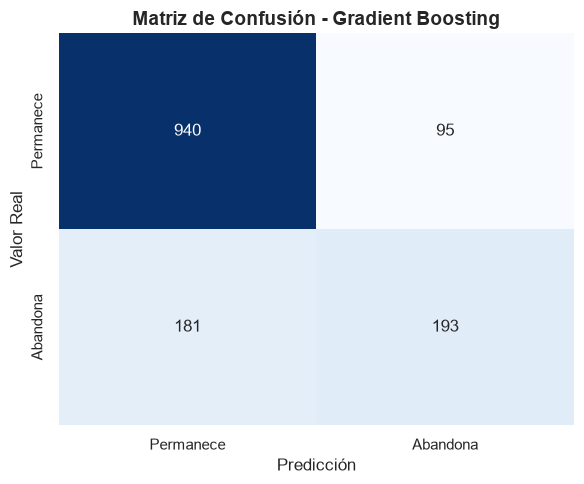

In [134]:
mejor_modelo_nombre = resultados_df.iloc[0]['Model']

mejor_pipeline = next(
    pipeline
    for pipeline, resultado in resultados
    if resultado['Model'] == mejor_modelo_nombre
)

graficar_matriz_confusion(
    mejor_pipeline,
    features_test,
    target_test,
    mejor_modelo_nombre
)

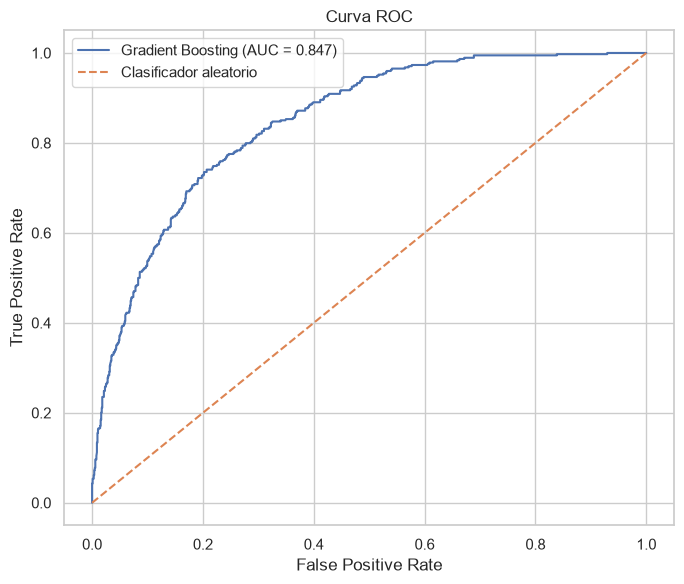

: 

In [ ]:


target_prob = mejor_pipeline.predict_proba(features_test)[:, 1]

fpr, tpr, thresholds = roc_curve(target_test, target_prob)

roc_auc = roc_auc_score(target_test, target_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f'{mejor_modelo_nombre} (AUC = {roc_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Clasificador aleatorio'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Curva ROC')
plt.legend()
plt.tight_layout()
plt.show()

### Conclusiones

El modelo seleccionado fue **Gradient Boosting**, al obtener el mejor desempeño en validación cruzada con un **ROC-AUC de 0.8466** y mantener un desempeño similar en el conjunto de prueba, con un **ROC-AUC de 0.8445**. Además, alcanzó una **accuracy de 80.5%** y una **precision de 67.5%**.

La matriz de confusión mostró **191 clientes correctamente identificados como posibles abandonos (TP)**, mientras que **183 clientes que realmente abandonaron fueron clasificados incorrectamente como permanentes (FN)**. Esto se refleja en un **recall de 51.1%**, por lo que existe margen para mejorar la detección de clientes en riesgo.

La curva ROC confirmó una buena capacidad de discriminación del modelo, con un **AUC de 0.845**, superior al obtenido por Random Forest (**0.838**), Logistic Regression (**0.825**) y Decision Tree (**0.824**). Por lo tanto, **Gradient Boosting presenta el mejor desempeño global según ROC-AUC**, aunque sería conveniente evaluar posteriormente distintos umbrales de clasificación para incrementar la detección de clientes con riesgo de abandono.


## 7. Conclusiones y recomendaciones

### 7.1. Conclusiones

El análisis permitió identificar que **1,869 de los 7,043 clientes (26.54%) abandonaron el servicio**, mientras que el **73.46% permaneció**. Además, el **55.02% de los clientes tiene contratos Month-to-month**, lo que representa un segmento relevante para las estrategias de retención.
El modelo seleccionado fue **Gradient Boosting**, con un **ROC-AUC de 0.8445 en prueba** y **0.8466 en validación cruzada**, mostrando un desempeño consistente. Su accuracy fue de aproximadamente **80%** y su precision de **67%**.
La matriz de confusión mostró **191 clientes correctamente identificados como posibles abandonos**, pero también **183 falsos negativos**. Esto representa una oportunidad de mejora en la detección de clientes que podrían cancelar el servicio. La curva ROC, con un AUC cercano a **0.84**, confirma una buena capacidad del modelo para distinguir entre clientes que abandonan y los que permanecen.

### 7.2. Recomendaciones de negocio



1. **Priorizar clientes con contratos Month-to-month.** Debido a que este segmento representa el **55.02% de la cartera**, se recomienda implementar campañas de retención específicas, como descuentos por permanencia, beneficios adicionales o incentivos para migrar a contratos de uno o dos años.

2. **Utilizar el modelo como sistema de alerta temprana.** Los clientes con mayor probabilidad de churn pueden ser enviados al equipo de marketing para realizar acciones preventivas antes de que ocurra la cancelación.

3. **Evaluar estrategias diferenciadas según cargos y servicios.** El análisis encontró una correlación de aproximadamente **0.65 entre MonthlyCharges y TotalCharges**, además de diferencias en los cargos según el tipo de contrato. Se recomienda diseñar ofertas que consideren el nivel de gasto y los servicios contratados por cada cliente.

4. **Optimizar el umbral de clasificación.** Aunque Gradient Boosting obtuvo el mejor ROC-AUC, su recall fue cercano al **51%**, por lo que se recomienda evaluar umbrales inferiores a 0.50 para aumentar la detección de clientes en riesgo, priorizando la reducción de falsos negativos.

5. **Fortalecer la estrategia de fidelización.** Considerando que la antigüedad del cliente se relaciona positivamente con los cargos totales, conservar a los clientes durante más tiempo puede contribuir a incrementar su valor acumulado. Por ello, se recomienda complementar las predicciones con programas de fidelización y beneficios asociados a la permanencia.

En conjunto, el modelo proporciona una herramienta útil para **identificar clientes con riesgo de abandono y orientar las acciones de retención**, aunque se recomienda continuar optimizando el umbral de decisión para mejorar la detección de clientes que efectivamente abandonarán el servicio.


# Informe

Se realizaron las principales etapas establecidas para el proyecto. Primero, se cargaron y revisaron los cuatro conjuntos de datos disponibles: `contract.csv`, `personal.csv`, `internet.csv` y `phone.csv`, utilizando `customerID` como identificador común. Posteriormente, se realizó un **análisis exploratorio de datos (EDA)** para conocer la estructura, los tipos de datos, los valores únicos, la distribución de las variables y las posibles inconsistencias.

Luego, se procedió a la **preparación de los datos y la definición de la variable objetivo**, donde `Churn = 1` representa a los clientes que abandonaron y `Churn = 0` a los que permanecieron. También se realizó la división de los datos, el balanceo de clases y la construcción del proceso de preprocesamiento mediante `Pipeline`, incluyendo imputación, estandarización y codificación de variables categóricas.

En la etapa de modelado se entrenaron y compararon **Logistic Regression, Random Forest, Gradient Boosting y Decision Tree**, utilizando además un **Dummy Classifier como modelo de referencia (*baseline*)**. Los hiperparámetros de los modelos principales fueron optimizados mediante `GridSearchCV`, utilizando **ROC-AUC como métrica principal**.

Finalmente, los modelos fueron evaluados utilizando **Accuracy, Precision, Recall, F1-score, ROC-AUC y matriz de confusión**, complementando la evaluación con una curva ROC para el modelo seleccionado.

No se realizaron etapas adicionales de optimización del **umbral de clasificación**. Esta etapa quedó como una posible mejora futura, debido a que el modelo final presenta un Recall de aproximadamente 51%, lo que indica un margen claro para incrementar la detección de clientes con riesgo de abandono.

**Desafíos enfrentados**

Principalmente, me **encontré dificultades** para definir cómo iba a manejar los **entrenamientos de los modelos**. Sin embargo, investigando, encontré la forma de generar una función con *pipelines* que me permitiera escribir un código más limpio y sin duplicar lógica. Esto facilitó iterar entre diferentes valores de **hiperparámetros** para encontrar la mejor configuración.

Al momento de definir las características en las columnas de servicios, encontré valores faltantes. Inicialmente, consideré que se reemplazarían con el valor más común, pero el revisor comentó acertadamente que esta falta de datos podría significar otra cosa. Por ello, decidí manejarlos como una nueva categoría: `'Missing'`.

**Pasos más importantes**

1.  **Integrar las diferentes fuentes de información** utilizando `customerID`, permitiendo construir una visión más completa de cada cliente.
2.  **Definir correctamente la variable objetivo `Churn`**, diferenciando entre clientes que abandonaron y clientes que permanecieron.
3.  **Preparar las variables para Machine Learning**, utilizando técnicas de imputación, escalamiento y *One-Hot Encoding* dentro de un *pipeline* de preprocesamiento.
4.  **Comparar diferentes algoritmos de clasificación** y utilizar un *Dummy Classifier* como referencia para determinar si los modelos desarrollados aportaban capacidad predictiva adicional.
5.  **Optimizar los hiperparámetros mediante validación cruzada**, utilizando ROC-AUC como criterio principal. En el caso de Gradient Boosting, se evaluaron 288 combinaciones mediante 5-*fold cross-validation*, obteniendo un ROC-AUC CV de **0.8466**.
6.  **Evaluar el modelo sobre datos no utilizados durante el entrenamiento**, verificando su capacidad de generalización mediante las métricas de clasificación, la matriz de confusión y la curva ROC.

**Modelo final y conclusiones**

El modelo final seleccionado fue **Gradient Boosting**, debido a que obtuvo el mejor desempeño según la métrica principal del proyecto. Alcanzó un **ROC-AUC de 0.8466 en validación cruzada** y aproximadamente **0.8445 en el conjunto de prueba**, mostrando un comportamiento consistente entre ambas evaluaciones.

En el conjunto de prueba, obtuvo aproximadamente:
*   **80.5% de Accuracy**
*   **67.5% de Precision**
*   **51.1% de Recall**
*   **58.1% de F1-score**

La matriz de confusión identificó correctamente **191 clientes que abandonaron**, aunque **183 clientes que efectivamente abandonaron fueron clasificados como permanentes**. Esto representa una oportunidad de mejora en la detección del *churn*.

De acuerdo con los criterios establecidos al inicio del proyecto, un **ROC-AUC de 0.8445** se encuentra en el rango **0.81–<0.85**, correspondiente a un desempeño de **4.5 SP**.

En conclusión, **Gradient Boosting presenta un buen nivel de calidad predictiva y una capacidad adecuada para distinguir entre clientes que abandonan y permanecen**, por lo que puede utilizarse como herramienta de apoyo para identificar clientes con mayor riesgo de *churn*. Sin embargo, debido a su Recall de aproximadamente **51%**, se recomienda como siguiente paso **optimizar el umbral de clasificación** para mejorar la detección de clientes que realmente abandonarán.